# Q2 — final revised version (for integration into `wildfires.ipynb`)

*Standalone working copy. The cells marked "standalone only" (this note, the setup cell and the section headers) are not copied into the group notebook. Every other cell keeps the cell id it has in `wildfires.ipynb` and replaces that cell; cells with ids `q2-rev-…` are new and go where they appear here. Note: cells `d524a81b` and `a6a85b5c` (the pre/post weekend comparison) have been removed and should also be deleted from `wildfires.ipynb`.*

**Changes relative to the Q2 currently in `wildfires.ipynb`**

1. **Active-day ($Y \ge 1$) vs. all-calendar-day ($Y \ge 0$) estimands:** Section 3.2 and Section 4.2 state clearly that `q2_daily_ignitions.xlsx` contains active days ($Y \ge 1$, answering how many ignitions occur given at least one), while the full post-2017 calendar ($Y \ge 0$, zeros included) directly answers the literal question on daily mean ignitions. Both analyses are presented as complementary and lead to the same inconclusive result (allowing a relative weekend increase of up to ~20 % on active days and ~31 % across all calendar days).
2. **Code-computed shares & skewness in Section 3.2:** Cell `2c425bf3` now computes and prints the share of fires with a recorded human cause by period (`36.4 %` pre-2017 vs. `90.7 %` post-2017, described as *recorded human cause* rather than an unproven claim about investigation rates), and Cell `fcbc3239` includes the sample skewness column (`skew`, $\approx 4.0$–$4.3$ post-2017).
3. **Cautious framing & `#### Summary` in Section 3.2:** Framed weekend leisure/agricultural burning as a *plausible mechanism*, smoothed the transition from Q1, corrected `"more than 75 %"` to `"at least 75 %"` for $\text{IQR} = 0.0$, and added `#### Summary` (`q2-rev-00`).
4. **Streamlined Section 4.2 & compact municipality table:** Removed Shapiro-Wilk, kurtosis and Levene/Brown-Forsythe; removed `"Simpson's paradox"`; trimmed the municipality table (`e1f7c150`) from 13 columns to the 8 essential columns (`Municipality`, `n_Weekend`, `n_Weekday`, `Mean_Weekend`, `Mean_Weekday`, `Diff (Wknd - Wkdy)`, `CI_95`, `p_value`); and noted that the two-proportion $Z$-test on active-day probabilities is a brief supplementary check.
5. **Removed pre/post weekend test:** Deleted `d524a81b` and `a6a85b5c` and updated Sections 5.2, 6.1 and 6.2.

In [1]:
# Standalone only: copy of the shared setup cell (Section 2.3 of wildfires.ipynb), not to be integrated
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.proportion as smp
from IPython.display import display

%matplotlib inline
%config InlineBackend.figure_format = "retina"

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

# ---------------------------------------------------------------- paths
project_path = Path.cwd()
raw = project_path / "01_dataset/raw"
processed = project_path / "01_dataset/processed"
processed.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------- fixed factor orders
MUNICIPALITIES = ["Chaves", "Montalegre", "Ourém", "Tomar"]
PERIOD_ORDER = ["Pre-2017", "Post-2017"]
CAUSE_ORDER = ["Intentional", "Negligent"]
SEASON_ORDER = ["Critical", "Non-Critical"]
DAY_ORDER = ["Weekday", "Weekend"]

# ---------------------------------- colours (colour-blind-safe set)
BLUE, ORANGE, GREEN, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"

PAL_PERIOD = dict(zip(PERIOD_ORDER, [BLUE, ORANGE]))
PAL_CAUSE = dict(zip(CAUSE_ORDER, [BLUE, ORANGE]))
PAL_SEASON = dict(zip(SEASON_ORDER, [BLUE, ORANGE]))
PAL_DAY = dict(zip(DAY_ORDER, [BLUE, ORANGE]))
PAL_MUN = dict(zip(MUNICIPALITIES, [BLUE, ORANGE, GREEN, YELLOW]))

# ------------------------------------------------ common plot style
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "font.sans-serif": ["DejaVu Sans"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})


def fig_title(fig, text):
    """Figure-level title for multi-panel figures, same look as the axes titles."""
    fig.suptitle(text, x=0.01, ha="left", fontsize=12, fontweight="bold")


def qq_panel(ax, values, color, title, ylabel="Sample quantiles"):
    """Normal Q-Q plot with a reference line through the quartiles."""
    (osm, osr), _ = stats.probplot(values, dist="norm")
    ax.scatter(osm, osr, s=6, color=color, alpha=.5, edgecolor="none")
    lo, hi = np.percentile(values, [25, 75])
    z_lo, z_hi = stats.norm.ppf([.25, .75])
    slope = (hi - lo) / (z_hi - z_lo)
    ax.plot(osm, lo + slope * (osm - z_lo), color=INK, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Theoretical quantiles")
    ax.set_ylabel(ylabel)

# Standalone only: in wildfires.ipynb df_final already exists (Section 2)
df_final = pd.read_excel(processed / "wildfires_processed.xlsx")

Python 3.12.3 | numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2 | seaborn 0.13.2


## 3) Explore Data

*(standalone header: not to be integrated)*

### 3.2 Q2: Daily Negligent Ignitions on Weekends and Weekdays

While Q1 examined how the balance between negligent and intentional fires shifted across seasons after 2017, Q2 focuses on the **weekly timing** of negligent ignitions in the post-2017 period (2018–2025): did the mean number of daily negligent wildfire ignitions differ significantly between weekends and weekdays across Chaves, Montalegre, Ourém and Tomar? A plausible mechanism is that recreational visits and small-scale agricultural burnings by part-time landholders are more frequent on weekends.

The unit of observation is a municipality-day. The file `q2_daily_ignitions.xlsx` contains only the municipality-days with at least one negligent ignition (*active days*, $Y \ge 1$). Days without ignitions are not missing: SGIF records every fire, so a municipality-day without a record had zero negligent ignitions. The descriptive statistics below and the first test in Section 4.2 evaluate active days ($E[Y \mid Y \ge 1]$: how many ignitions occur given at least one), while Section 4.2 also evaluates all calendar days ($E[Y]$ with zeros included, which directly addresses the unconditional daily mean in the wording of Q2). Both periods are shown below for descriptive context, although direct pre- vs. post-2017 count comparisons are limited because the share of fires with a recorded human cause (intentional or negligent) rose from 36.4 % before 2017 to 90.7 % after 2017.

**Zero-area records ($0\text{ ha}$).** Negligent ignitions are counted whatever their final burnt area, because Q2 concerns ignitions and not fire size. Only 3 of the 4,349 negligent records in the two periods have a burnt area of $0\text{ ha}$, so this choice has no practical effect on the counts. Because count variables present strong positive skewness, both robust measures (median, IQR) and parametric metrics (mean, standard deviation, skewness) are reported.

#### Data

In [2]:
q2 = pd.read_excel(processed / "q2_daily_ignitions.xlsx")

# fixed data types and factor orders
q2["Date"] = pd.to_datetime(q2["Date"])
q2["Period"] = pd.Categorical(q2["Period"], categories=PERIOD_ORDER, ordered=True)
q2["Day_Type"] = pd.Categorical(q2["Day_Type"], categories=DAY_ORDER, ordered=True)

# consistency with the record-level data and share of fires with a recorded human cause
neg_records = df_final[(df_final["Cause_Type"] == "Negligent") & (df_final["Period"] != "Transition")]
assert q2["Daily_Ignitions_Count"].sum() == len(neg_records)
cause_recorded = (df_final[df_final["Period"] != "Transition"]
                  .groupby("Period", observed=False)["Cause_Type"]
                  .apply(lambda s: s.notna().mean()))
print(f"Negligent records (pre- and post-2017): {len(neg_records):,}; "
      f"with 0 ha burnt: {(neg_records['Total_Burnt_Area'] == 0).sum()}")
print(f"Share of fires with a recorded human cause (Intentional or Negligent): "
      f"Pre-2017 = {cause_recorded['Pre-2017']:.1%}, Post-2017 = {cause_recorded['Post-2017']:.1%}")

q2.info()
q2.head()

Negligent records (pre- and post-2017): 4,349; with 0 ha burnt: 3
Share of fires with a recorded human cause (Intentional or Negligent): Pre-2017 = 36.4%, Post-2017 = 90.7%
<class 'pandas.DataFrame'>
RangeIndex: 2897 entries, 0 to 2896
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Concelho               2897 non-null   str           
 1   Date                   2897 non-null   datetime64[us]
 2   Period                 2897 non-null   category      
 3   Daily_Ignitions_Count  2897 non-null   int64         
 4   Day_Type               2897 non-null   category      
dtypes: category(2), datetime64[us](1), int64(1), str(1)
memory usage: 95.5 KB


,Concelho,Date,Period,Daily_Ignitions_Count,Day_Type
0,Chaves,2001-07-21,Pre-2017,1,Weekend
1,Chaves,2001-07-29,Pre-2017,1,Weekend
2,Chaves,2001-08-10,Pre-2017,1,Weekday
3,Chaves,2001-08-13,Pre-2017,1,Weekday
4,Chaves,2001-08-16,Pre-2017,1,Weekday


#### Descriptive statistics

In [3]:
# Summary statistics by Period and Day_Type (including skewness)
summary_stats = (
    q2.groupby(["Period", "Day_Type"], observed=False)["Daily_Ignitions_Count"]
    .agg(
        n="count",
        mean="mean",
        std="std",
        median="median",
        iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
        min="min",
        max="max",
        skew=lambda x: stats.skew(x),
    )
    .reset_index()
)

# standard error of the mean (SEM)
summary_stats["sem"] = summary_stats["std"] / np.sqrt(summary_stats["n"])

print("Summary statistics for daily negligent ignitions (active days):")
display(summary_stats.round(3))

Summary statistics for daily negligent ignitions (active days):


,Period,Day_Type,n,mean,std,median,iqr,min,max,skew,sem
0,Pre-2017,Weekday,1253,1.505,1.056,1.0,1.0,1,10,3.158,0.030
1,Pre-2017,Weekend,505,1.519,1.067,1.0,1.0,1,8,2.872,0.047
2,Post-2017,Weekday,802,1.455,1.161,1.0,0.0,1,11,4.257,0.041
3,Post-2017,Weekend,337,1.570,1.402,1.0,1.0,1,12,4.025,0.076


#### Distribution of daily negligent ignitions

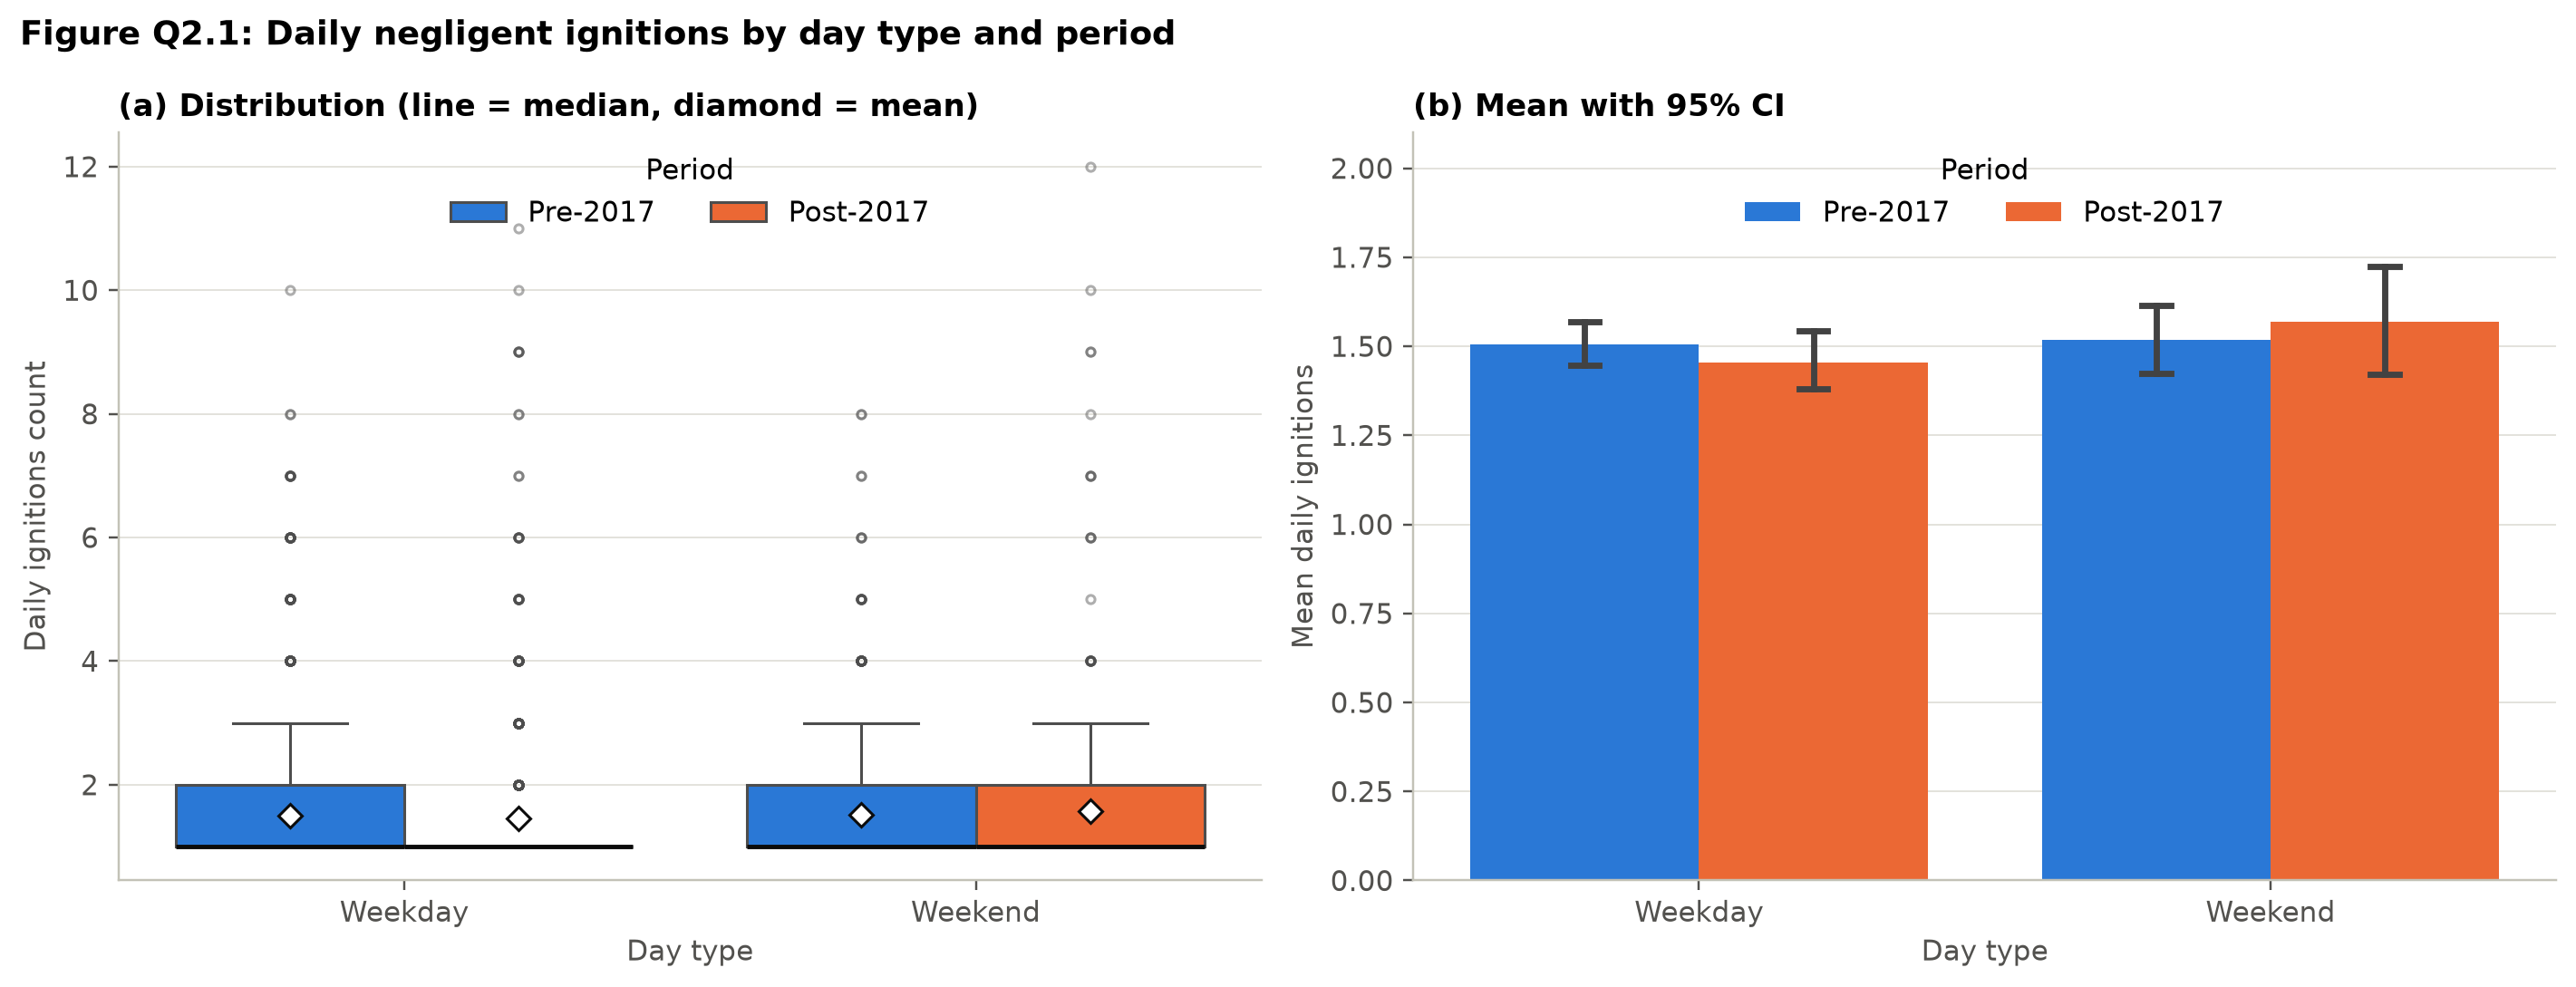

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Boxplot
sns.boxplot(
    data=q2, x="Day_Type", y="Daily_Ignitions_Count", hue="Period",
    order=DAY_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD, saturation=1,
    ax=axes[0], showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": INK, "markersize": 6},
    medianprops={"color": INK, "linewidth": 1.6},
    flierprops={"marker": "o", "markersize": 3, "alpha": .45},
)
axes[0].set_title("(a) Distribution (line = median, diamond = mean)")
axes[0].set_xlabel("Day type")
axes[0].set_ylabel("Daily ignitions count")
axes[0].legend(title="Period", loc="upper center", ncol=2)

# (b) Means with 95% CI
sns.barplot(
    data=q2, x="Day_Type", y="Daily_Ignitions_Count", hue="Period",
    order=DAY_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD, saturation=1,
    errorbar=("ci", 95), capsize=0.1, ax=axes[1]
)
axes[1].set_title("(b) Mean with 95% CI")
axes[1].set_xlabel("Day type")
axes[1].set_ylabel("Mean daily ignitions")
axes[1].set_ylim(0, 2.1)
axes[1].legend(title="Period", loc="upper center", ncol=2)

fig_title(fig, "Figure Q2.1: Daily negligent ignitions by day type and period")
plt.tight_layout()
plt.show()

Figure Q2.1(a) shows that on active fire days the distribution of daily negligent ignitions is strongly right-skewed in every group (post-2017 skewness $= 4.26$ on weekdays and $4.02$ on weekends), with a median of $1.0$ ignition/day (in the post-2017 weekday group, at least 75 % of active days had a single ignition, so $\text{IQR} = 0.0$, while occasional extreme days reach $11$ or $12$ ignitions). Figure Q2.1(b) shows that in the post-2017 period the sample mean is slightly higher on weekends ($1.570$) than on weekdays ($1.455$), but the 95 % confidence intervals overlap substantially.

#### Summary

Across the $2,897$ active municipality-days ($1,139$ in the post-2017 period), daily negligent ignition counts are strongly right-skewed (post-2017 skewness $\approx 4.0$–$4.3$) and concentrated at $1$ ignition per active day on both weekdays and weekends. In 2018–2025, the sample mean on active days is $+0.115$ ignitions/day higher on weekends ($1.570$, $\text{SD} = 1.402$, $n = 337$) than on weekdays ($1.455$, $\text{SD} = 1.161$, $n = 802$), with overlapping 95 % confidence intervals. Whether this post-2017 difference is statistically significant—both on active days and across all calendar days—is tested in Section 4.2.

---

## 4) Draw Inferences

*(standalone header: not to be integrated)*

### 4.2 Q2: Welch's Two-Sample t-test

We aim to test whether the mean number of daily negligent ignitions differs significantly between weekends and weekdays in the post-2017 period.

#### Terminology

- **$\mu_{\text{Weekend}}$**: Population mean number of negligent ignitions per municipality-day on active weekend days (days with at least one negligent ignition) in the post-2017 period, $E[Y \mid Y \ge 1, \text{weekend}]$ ($n_1 = 337$).
- **$\mu_{\text{Weekday}}$**: The same for active weekdays, $E[Y \mid Y \ge 1, \text{weekday}]$ ($n_2 = 802$).
- **$\alpha$**: The significance level, set at 0.05.

#### Hypotheses

- **$H_0$**: $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} = 0$ (on active days, there is no difference in the population mean daily negligent ignitions between weekends and weekdays).
- **$H_1$**: $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} \neq 0$ (two-sided: on active days, the population mean daily negligent ignitions differ between weekends and weekdays).

Because `q2_daily_ignitions.xlsx` records only active days ($Y \ge 1$), this primary test answers whether fire-active days have more ignitions on weekends than on weekdays. The unconditional daily mean over all calendar days ($E[Y]$ for $Y \ge 0$, zeros included)—which directly corresponds to the literal wording of Q2—is analysed right after the municipality and same-day dependence checks; the two analyses are complementary and lead to the same conclusion.

#### Checking the assumptions

A two-sample $t$-test requires three conditions:

1. **Independence:** Each observation represents a distinct municipal active fire day (`Concelho` $\times$ `Date`). Observations on the same date in different municipalities share the same weather and the same day type, so they are not fully independent; a robustness check below uses standard errors clustered by date (temporal dependence between consecutive days is discussed in the limitations in Section 6).
2. **Normality:** Assessed visually via histograms and normal Q-Q plots (Figure Q2.2). Because active-day ignition counts are discrete integers ($\ge 1$) with strong right-skewness (skewness $= 4.26$ on weekdays and $4.02$ on weekends), the raw observations are not normal. However, given the large sample sizes ($n_{\text{Weekend}} = 337 \ge 30$ and $n_{\text{Weekday}} = 802 \ge 30$), the sampling distribution of the sample means is **approximately normal by the Central Limit Theorem (CLT)**, although strong positive skewness can slow convergence.
3. **Variances:** The sample standard deviations are $1.402$ on weekends and $1.161$ on weekdays (SD ratio $= 1.21$, variance ratio $= 1.46$). **Welch's two-sample $t$-test** (`equal_var=False`) is used as the primary parametric test because it adjusts the degrees of freedom (Welch-Satterthwaite) and does not assume equal variances.

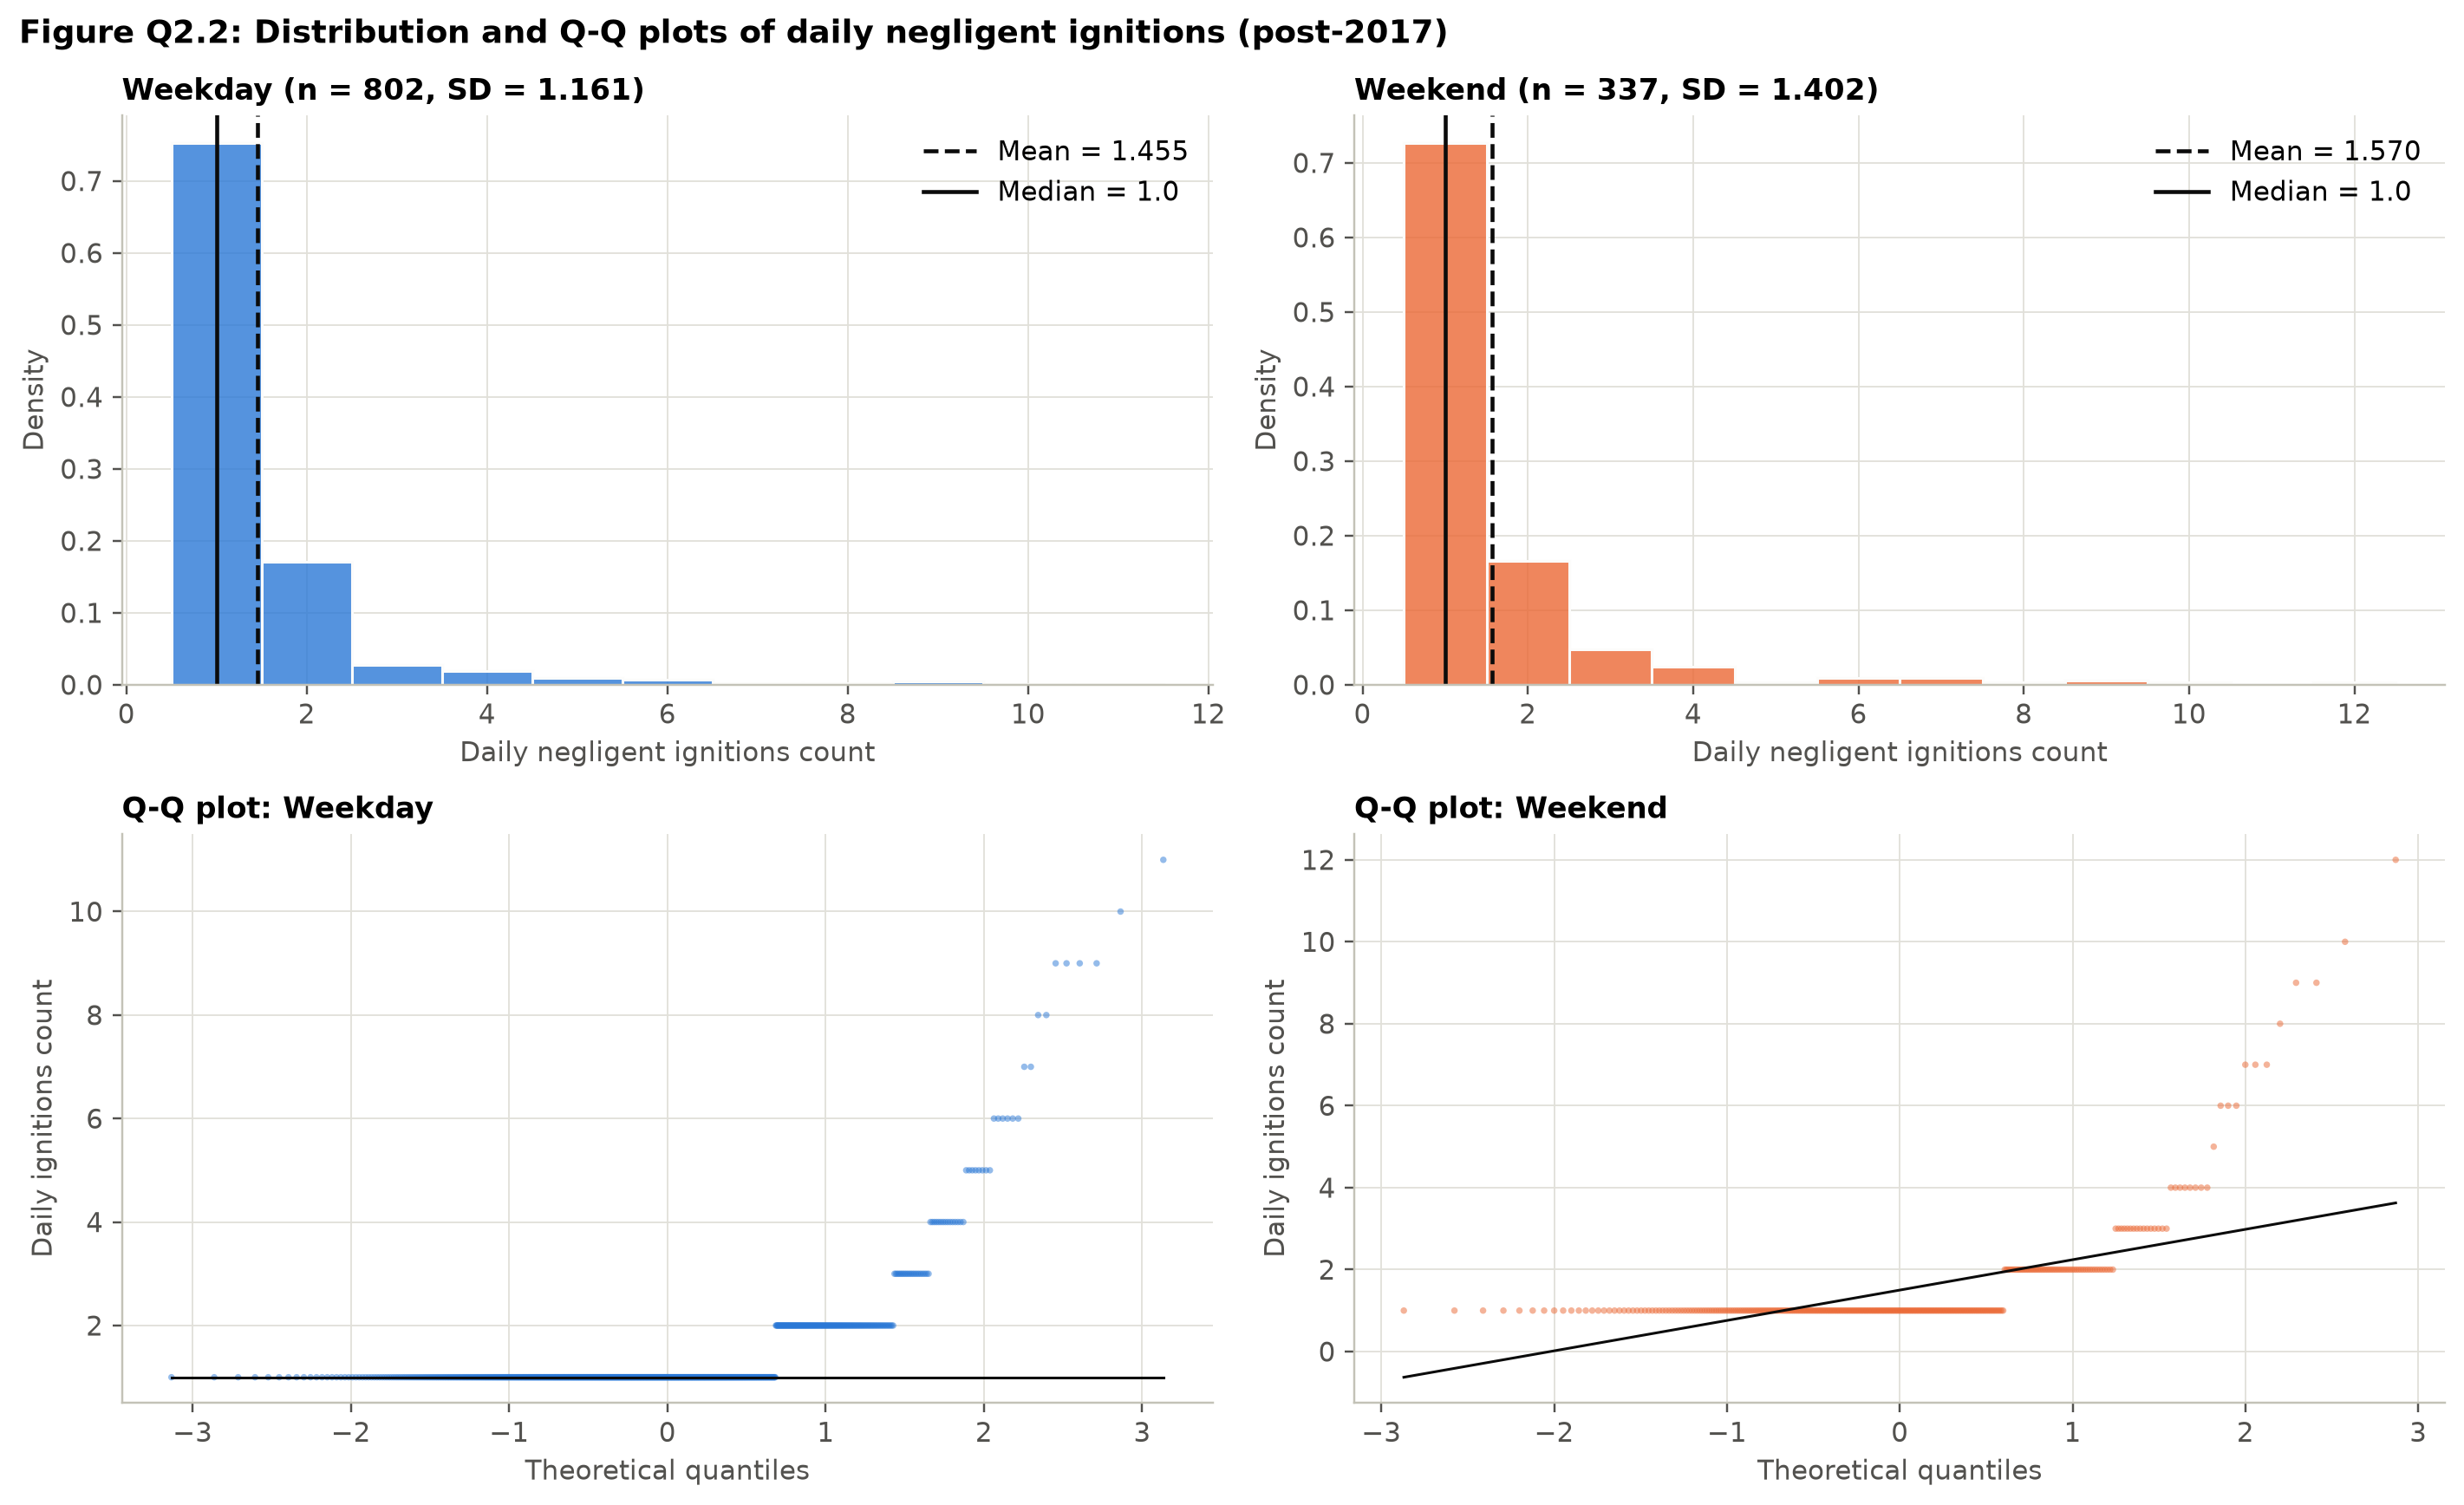

Post-2017 spread: Weekend SD = 1.402 (var = 1.966) | Weekday SD = 1.161 (var = 1.347) | SD ratio = 1.21 (variance ratio = 1.46)


In [5]:
# Post-2017 subset
post_data = q2[q2["Period"] == "Post-2017"].copy()

weekday_post = post_data[post_data["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
weekend_post = post_data[post_data["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]

# Visual check of normality and spread: histograms + Q-Q plots (post-2017)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
groups_post = [("Weekday", weekday_post), ("Weekend", weekend_post)]

for i, (label, serie) in enumerate(groups_post):
    color = PAL_DAY[label]
    # histogram (top row)
    sns.histplot(serie, discrete=True, stat="density", color=color, alpha=0.8, edgecolor=SURFACE, ax=axes[0, i])
    axes[0, i].axvline(serie.mean(), color=INK, linestyle="--", linewidth=1.5, label=f"Mean = {serie.mean():.3f}")
    axes[0, i].axvline(serie.median(), color=INK, linestyle="-", linewidth=1.5, label=f"Median = {serie.median():.1f}")
    axes[0, i].set_title(f"{label} (n = {len(serie)}, SD = {serie.std(ddof=1):.3f})")
    axes[0, i].set_xlabel("Daily negligent ignitions count")
    axes[0, i].set_ylabel("Density")
    axes[0, i].legend()

    # normal Q-Q plot (bottom row)
    qq_panel(axes[1, i], serie, color, f"Q-Q plot: {label}", ylabel="Daily ignitions count")

fig_title(fig, "Figure Q2.2: Distribution and Q-Q plots of daily negligent ignitions (post-2017)")
plt.tight_layout()
plt.show()

var_ratio = weekend_post.var(ddof=1) / weekday_post.var(ddof=1)
print(f"Post-2017 spread: Weekend SD = {weekend_post.std(ddof=1):.3f} (var = {weekend_post.var(ddof=1):.3f}) | "
      f"Weekday SD = {weekday_post.std(ddof=1):.3f} (var = {weekday_post.var(ddof=1):.3f}) | "
      f"SD ratio = {np.sqrt(var_ratio):.2f} (variance ratio = {var_ratio:.2f})")

#### Welch's t-test

In [6]:
# Welch's t-test (equal_var=False)
t_stat, p_val = stats.ttest_ind(weekend_post, weekday_post, equal_var=False)

# Welch-Satterthwaite degrees of freedom
s1, s2 = np.var(weekend_post, ddof=1), np.var(weekday_post, ddof=1)
n1, n2 = len(weekend_post), len(weekday_post)
df_welch = ((s1 / n1 + s2 / n2) ** 2) / (
    ((s1 / n1) ** 2) / (n1 - 1) + ((s2 / n2) ** 2) / (n2 - 1)
)

# Critical value (two-sided, alpha = 0.05) and 95% confidence interval
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha / 2, df=df_welch)
diff_mean = weekend_post.mean() - weekday_post.mean()
se_diff = np.sqrt(s1 / n1 + s2 / n2)
ci_low, ci_high = stats.t.interval(
    1 - alpha, df=df_welch, loc=diff_mean, scale=se_diff
)

print("Welch's two-sample t-test (post-2017):")
print(f"Mean Weekend: {weekend_post.mean():.3f} (SD = {weekend_post.std(ddof=1):.3f}, n = {n1})")
print(f"Mean Weekday: {weekday_post.mean():.3f} (SD = {weekday_post.std(ddof=1):.3f}, n = {n2})")
print(f"Difference in means (Weekend - Weekday): {diff_mean:.3f} (SE = {se_diff:.4f})")
print(f"Welch t-statistic (t_obs): {t_stat:.4f}")
print(f"Degrees of freedom (df): {df_welch:.2f}")
print(f"Critical value (t_crit, alpha = 0.05 two-sided): ±{t_crit:.4f}")
print(f"p-value: {p_val:.4f}")
print(f"95% confidence interval for the difference: [{ci_low:.3f}, {ci_high:.3f}]")
decision = "Reject H0" if p_val < alpha else "Fail to reject H0"
print(f"Decision: {decision} (|t_obs| = {abs(t_stat):.4f}, t_crit = {t_crit:.4f}, p = {p_val:.4f}, alpha = {alpha})")

# Effect size: ratio of means and Cohen's d (pooled SD)
mean_ratio = weekend_post.mean() / weekday_post.mean()
sd_pooled = np.sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
cohen_d = diff_mean / sd_pooled
print(f"\nEffect size: ratio of means (Weekend / Weekday) = {mean_ratio:.3f} ({100 * (mean_ratio - 1):+.1f} %), Cohen's d = {cohen_d:.3f}")
print(f"95% CI for the difference relative to the weekday mean: "
      f"[{100 * ci_low / weekday_post.mean():+.1f} %, {100 * ci_high / weekday_post.mean():+.1f} %]")

Welch's two-sample t-test (post-2017):
Mean Weekend: 1.570 (SD = 1.402, n = 337)
Mean Weekday: 1.455 (SD = 1.161, n = 802)
Difference in means (Weekend - Weekday): 0.115 (SE = 0.0867)
Welch t-statistic (t_obs): 1.3223
Degrees of freedom (df): 538.57
Critical value (t_crit, alpha = 0.05 two-sided): ±1.9644
p-value: 0.1866
95% confidence interval for the difference: [-0.056, 0.285]
Decision: Fail to reject H0 (|t_obs| = 1.3223, t_crit = 1.9644, p = 0.1866, alpha = 0.05)

Effect size: ratio of means (Weekend / Weekday) = 1.079 (+7.9 %), Cohen's d = 0.093
95% CI for the difference relative to the weekday mean: [-3.8 %, +19.6 %]


#### Robustness check: controlling for municipality

As shown in the table below, the four municipalities differ substantially in daily negligent ignition counts, with the weekend mean ranging from about $1.05$ ignitions/day in `Tomar` to $1.99$ ignitions/day in `Montalegre` (and the weekday mean ranging from $1.08$ in `Ourém` to $1.82$ in `Montalegre`). To verify that pooling the observations across `Chaves`, `Montalegre`, `Ourém` and `Tomar` does not mask a municipality-specific weekend effect, we repeat Welch's two-sample $t$-test separately within each municipality and plot the 95 % confidence intervals for the difference in means ($\mu_{\text{Weekend}} - \mu_{\text{Weekday}}$). Applying a Bonferroni correction across the $K = 4$ municipal tests ($\alpha_{\text{Bonf}} = 0.05 / 4 = 0.0125$) does not change the conclusion, as $p > 0.05$ in every municipality.

Welch's t-test by municipality (Bonferroni alpha = 0.05/4 = 0.0125; all p > 0.05):


,Municipality,n_Weekend,n_Weekday,Mean_Weekend,Mean_Weekday,Diff (Wknd - Wkdy),CI_95,p_value
0,Chaves,84,181,1.369,1.238,0.131,"[-0.028, 0.291]",0.1063
1,Montalegre,153,363,1.993,1.824,0.170,"[-0.178, 0.517]",0.3365
2,Ourém,44,131,1.136,1.084,0.052,"[-0.065, 0.170]",0.3754
3,Tomar,56,127,1.054,1.094,-0.041,"[-0.137, 0.056]",0.4029
4,All (pooled),337,802,1.570,1.455,0.115,"[-0.056, 0.285]",0.1866


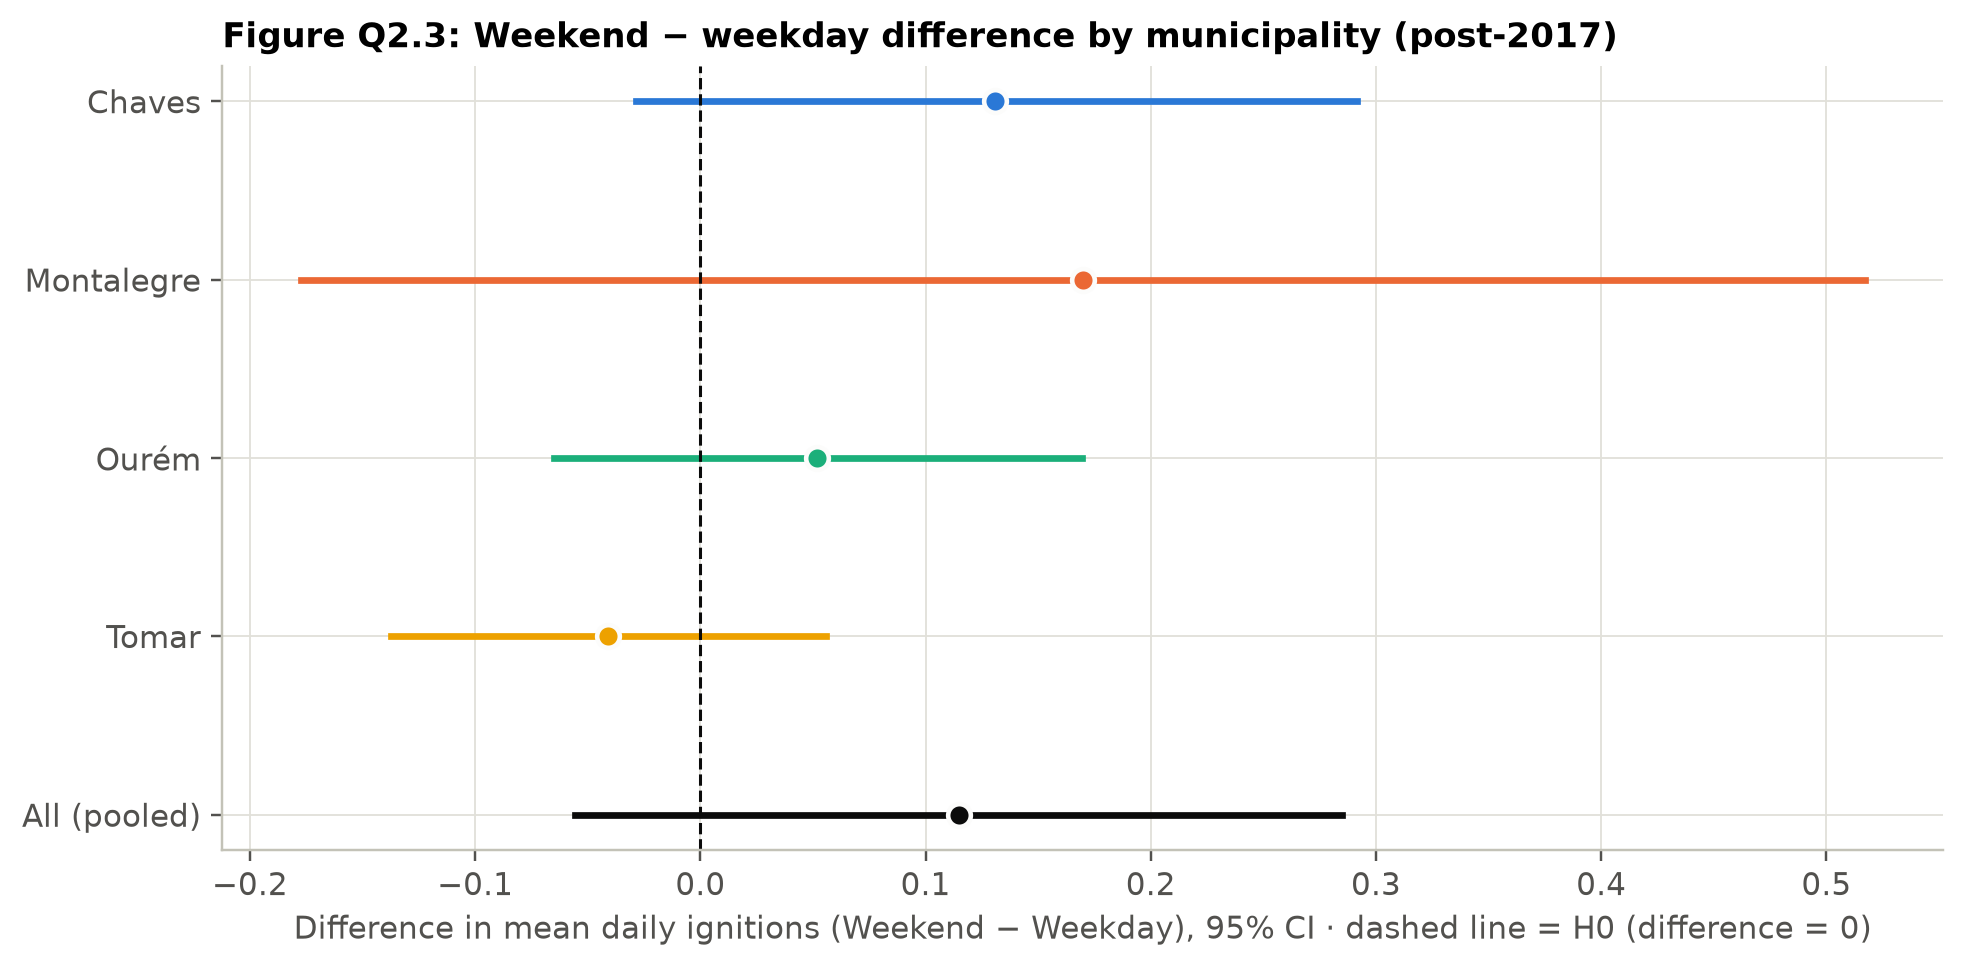

In [7]:
# Welch's t-test by municipality in the post-2017 period
alpha_bonf_mun = 0.05 / 4  # Bonferroni correction for 4 municipalities (0.0125)
mun_rows = []
for mun in MUNICIPALITIES:
    sub_m = post_data[post_data["Concelho"] == mun]
    wknd_m = sub_m[sub_m["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]
    wkdy_m = sub_m[sub_m["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
    if len(wknd_m) >= 2 and len(wkdy_m) >= 2:
        t_m, p_m = stats.ttest_ind(wknd_m, wkdy_m, equal_var=False)
        v1_m, v2_m = wknd_m.var(ddof=1), wkdy_m.var(ddof=1)
        n1_m, n2_m = len(wknd_m), len(wkdy_m)
        se_m = np.sqrt(v1_m / n1_m + v2_m / n2_m)
        df_m = ((v1_m / n1_m + v2_m / n2_m) ** 2) / (((v1_m / n1_m) ** 2) / (n1_m - 1) + ((v2_m / n2_m) ** 2) / (n2_m - 1))
        diff_m = wknd_m.mean() - wkdy_m.mean()
        ci_l, ci_h = stats.t.interval(0.95, df=df_m, loc=diff_m, scale=se_m)
        mun_rows.append({
            "Municipality": mun,
            "n_Weekend": n1_m,
            "n_Weekday": n2_m,
            "Mean_Weekend": round(wknd_m.mean(), 3),
            "Mean_Weekday": round(wkdy_m.mean(), 3),
            "Diff (Wknd - Wkdy)": round(diff_m, 3),
            "CI_95": f"[{ci_l:.3f}, {ci_h:.3f}]",
            "p_value": round(p_m, 4),
            "CI_95_low": ci_l,
            "CI_95_high": ci_h,
        })

# Pooled row (all municipalities, post-2017) for visual comparison
mun_rows.append({
    "Municipality": "All (pooled)",
    "n_Weekend": n1,
    "n_Weekday": n2,
    "Mean_Weekend": round(weekend_post.mean(), 3),
    "Mean_Weekday": round(weekday_post.mean(), 3),
    "Diff (Wknd - Wkdy)": round(diff_mean, 3),
    "CI_95": f"[{ci_low:.3f}, {ci_high:.3f}]",
    "p_value": round(p_val, 4),
    "CI_95_low": ci_low,
    "CI_95_high": ci_high,
})

mun_df = pd.DataFrame(mun_rows)
cols_show = ["Municipality", "n_Weekend", "n_Weekday", "Mean_Weekend", "Mean_Weekday", "Diff (Wknd - Wkdy)", "CI_95", "p_value"]
print(f"Welch's t-test by municipality (Bonferroni alpha = 0.05/4 = {alpha_bonf_mun:.4f}; all p > 0.05):")
display(mun_df[cols_show])

# Forest plot of the 95% confidence intervals for (mu_Weekend - mu_Weekday)
fig, ax = plt.subplots(figsize=(9, 4.5))
y_pos = np.arange(len(mun_df))

for idx, row in mun_df.iterrows():
    col = INK if row["Municipality"] == "All (pooled)" else PAL_MUN[row["Municipality"]]
    ax.plot([row["CI_95_low"], row["CI_95_high"]], [idx, idx], color=col, linewidth=2.2)
    ax.scatter(row["Diff (Wknd - Wkdy)"], idx, s=55, color=col, zorder=3, edgecolor=SURFACE, linewidth=1.5)

ax.axvline(0, color=INK, linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(mun_df["Municipality"])
ax.invert_yaxis()
ax.set_xlabel("Difference in mean daily ignitions (Weekend − Weekday), 95% CI · dashed line = H0 (difference = 0)")
ax.set_title("Figure Q2.3: Weekend − weekday difference by municipality (post-2017)")
plt.tight_layout()
plt.show()

#### Robustness check: dependence between municipalities on the same day

The municipalities are close to each other in pairs (Chaves and Montalegre, Ourém and Tomar), and on many dates more than one municipality had negligent ignitions. Observations sharing a date are exposed to the same weather and always have the same day type, so the Welch standard error may be too small. The difference in means is therefore re-estimated as a regression on a weekend indicator (its coefficient equals the difference in means) with standard errors clustered by date.

In [8]:
# Same-day dependence: share of active dates with more than one active municipality
mun_per_date = post_data.groupby("Date").size()
print(f"Post-2017 active dates: {len(mun_per_date):,}; with more than one active municipality: {(mun_per_date > 1).mean():.1%}")

# Difference in means (Weekend - Weekday) with standard errors clustered by date
reg_data = post_data.assign(weekend=(post_data["Day_Type"] == "Weekend").astype(int))
ols_cl = smf.ols("Daily_Ignitions_Count ~ weekend", data=reg_data).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(reg_data["Date"])[0]})
ci_cl = ols_cl.conf_int().loc["weekend"]
print(f"Difference = {ols_cl.params['weekend']:.3f}, SE clustered by date = {ols_cl.bse['weekend']:.4f} "
      f"(Welch SE = {se_diff:.4f}), p = {ols_cl.pvalues['weekend']:.4f}, 95% CI [{ci_cl.iloc[0]:.3f}, {ci_cl.iloc[1]:.3f}]")

Post-2017 active dates: 869; with more than one active municipality: 27.0%
Difference = 0.115, SE clustered by date = 0.0885 (Welch SE = 0.0867), p = 0.1955, 95% CI [-0.059, 0.288]


#### Unconditional analysis: all calendar days (including days without ignitions)

While the primary test above evaluates active fire days ($Y \ge 1$), the literal wording of Q2—the mean number of daily negligent ignitions—corresponds to the unconditional daily mean across all calendar days, including days with zero ignitions. Reconstructing the full post-2017 calendar (every municipality-day from 1 January 2018 to the last alert in the data, $N = 11,460$) gives the unconditional mean $E[Y]$, which factors as

$$E[Y] = P(Y \ge 1) \times E[Y \mid Y \ge 1],$$

the probability that a municipality-day has at least one negligent ignition times the mean on active days. Together, the active-day and full-calendar analyses provide a complete answer: we compare the unconditional means $E[Y]$ using Welch's $t$-test (and with standard errors clustered by date), and include a brief supplementary two-proportion $Z$-test on $P(Y \ge 1)$ to check whether the probability of an active day differs between weekends and weekdays.

In [9]:
# Full post-2017 calendar: every municipality x day from 1 Jan 2018 to the last alert in the data
last_day = df_final["DataHoraAlerta"].max().normalize()
calendar = pd.MultiIndex.from_product([MUNICIPALITIES, pd.date_range("2018-01-01", last_day)], names=["Concelho", "Date"])
cal = (post_data.set_index(["Concelho", "Date"])["Daily_Ignitions_Count"]
       .reindex(calendar, fill_value=0).reset_index())
cal["Day_Type"] = pd.Categorical(np.where(cal["Date"].dt.day_of_week >= 5, "Weekend", "Weekday"), categories=DAY_ORDER)
assert cal["Daily_Ignitions_Count"].sum() == post_data["Daily_Ignitions_Count"].sum()
print(f"Calendar: {cal['Date'].min():%Y-%m-%d} to {cal['Date'].max():%Y-%m-%d}, {len(cal):,} municipality-days")

# Decomposition E[Y] = P(Y >= 1) x E[Y | Y >= 1]
decomp = cal.groupby("Day_Type", observed=False)["Daily_Ignitions_Count"].agg(
    municipality_days="size",
    active_days=lambda y: (y > 0).sum(),
    p_active=lambda y: (y > 0).mean(),
    mean_active_days=lambda y: y[y > 0].mean(),
    mean_all_days="mean",
)
display(decomp.round(4))

y_we = cal.loc[cal["Day_Type"] == "Weekend", "Daily_Ignitions_Count"]
y_wd = cal.loc[cal["Day_Type"] == "Weekday", "Daily_Ignitions_Count"]

# (a) unconditional mean: Welch's t-test and the same difference with standard errors clustered by date
t_all = stats.ttest_ind(y_we, y_wd, equal_var=False)
ci_all = t_all.confidence_interval(0.95)
diff_all = y_we.mean() - y_wd.mean()
print(f"Mean over all days: Weekend {y_we.mean():.4f} vs Weekday {y_wd.mean():.4f} "
      f"(diff = {diff_all:+.4f}, ratio = {y_we.mean() / y_wd.mean():.3f} or {100 * (y_we.mean() / y_wd.mean() - 1):+.1f} %)")
print(f"  Welch t({t_all.df:.1f}) = {t_all.statistic:.3f}, p = {t_all.pvalue:.4f}, "
      f"95% CI for the difference [{ci_all.low:.4f}, {ci_all.high:.4f}] "
      f"([{100 * ci_all.low / y_wd.mean():+.1f} %, {100 * ci_all.high / y_wd.mean():+.1f} %] of weekday mean)")
ols_all = smf.ols("Daily_Ignitions_Count ~ weekend", data=cal.assign(weekend=(cal["Day_Type"] == "Weekend").astype(int))).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(cal["Date"])[0]})
print(f"  SE clustered by date: p = {ols_all.pvalues['weekend']:.4f}")

# (b) supplementary check on probability of an active day: two-proportion Z-test
z_act, p_act = smp.proportions_ztest([(y_we > 0).sum(), (y_wd > 0).sum()], [len(y_we), len(y_wd)])
print(f"Supplementary check — P(Y >= 1): Weekend {(y_we > 0).mean():.3f} vs Weekday {(y_wd > 0).mean():.3f}; "
      f"Z = {z_act:.3f}, p = {p_act:.4f}")

Calendar: 2018-01-01 to 2025-11-04, 11,460 municipality-days


,municipality_days,active_days,p_active,mean_active_days,mean_all_days
Day_Type,,,,,
Weekday,8188,802,0.0979,1.4551,0.1425
Weekend,3272,337,0.1030,1.5697,0.1617


Mean over all days: Weekend 0.1617 vs Weekday 0.1425 (diff = +0.0191, ratio = 1.134 or +13.4 %)
  Welch t(5312.2) = 1.468, p = 0.1423, 95% CI for the difference [-0.0064, 0.0447] ([-4.5 %, +31.4 %] of weekday mean)
  SE clustered by date: p = 0.1925
Supplementary check — P(Y >= 1): Weekend 0.103 vs Weekday 0.098; Z = 0.816, p = 0.4147


---

## 5) Formulate Conclusions

*(standalone header: not to be integrated)*

### 5.2 Q2: Daily Negligent Ignitions on Weekends and Weekdays

**Statistical decision**

- **Significance level:** $\alpha = 0.05$.
- **Active fire days ($Y \ge 1$, conditional mean $E[Y \mid Y \ge 1]$):**
  - Weekday: $\bar{x} = 1.455$ ($s = 1.161$, $\text{median} = 1.0$, $\text{IQR} = 0.0$, $n_{\text{Weekday}} = 802$)
  - Weekend: $\bar{x} = 1.570$ ($s = 1.402$, $\text{median} = 1.0$, $\text{IQR} = 1.0$, $n_{\text{Weekend}} = 337$)
  - Difference in sample means ($\bar{x}_{\text{Weekend}} - \bar{x}_{\text{Weekday}}$): $+0.115$ ignitions/day ($\text{SE} = 0.0867$), Welch's $t_{\text{obs}}(538.57) = 1.3223$, $t_{\text{crit}} = \pm 1.9644$, $p = 0.1866$.
  - 95 % confidence interval: $[-0.056, \, 0.285]$ (relative to the weekday mean, $-3.8\,\%$ to $+19.6\,\%$; ratio of means $= 1.079$ or $+7.9\,\%$, Cohen's $d = 0.09$).
- **All calendar days ($Y \ge 0$, unconditional mean $E[Y]$ answering the literal question):**
  - Weekday: $\bar{x} = 0.1425$ ($n = 8,188$ municipality-days) vs. Weekend: $\bar{x} = 0.1617$ ($n = 3,272$ municipality-days).
  - Difference in sample means: $+0.0191$ ignitions/day (ratio $= 1.134$ or $+13.4\,\%$), Welch's $t(5312.2) = 1.468$, $p = 0.1423$ ($p = 0.1925$ with date-clustered standard errors).
  - 95 % confidence interval: $[-0.0064, \, 0.0447]$, which corresponds to $-4.5\,\%$ to $+31.4\,\%$ of the weekday mean.

Because $p > \alpha = 0.05$ in both analyses (and both 95 % confidence intervals include zero, with $|t_{\text{obs}}| = 1.3223 < t_{\text{crit}} = 1.9644$ on active days), we **fail to reject the null hypothesis ($H_0$)** at the 5 % significance level. The result is **inconclusive**: there is insufficient statistical evidence that the mean number of daily negligent ignitions differs between weekends and weekdays in the post-2017 period. The data are compatible with no effect, while leaving room for a possible weekend increase of up to about $20\,\%$ on active fire days or about one third ($+31\,\%$) across all calendar days.

**Contextual discussion**

1. **Complementary active-day and full-calendar perspectives:** Because $E[Y] = P(Y \ge 1) \times E[Y \mid Y \ge 1]$, the unconditional daily mean combines the probability of an active day ($10.3\,\%$ on weekends vs. $9.8\,\%$ on weekdays; supplementary $Z = 0.816, p = 0.4147$) and the mean count on active days ($1.570$ vs. $1.455$; $p = 0.1866$). Both components show a small, non-significant weekend excess, and the median on active days is $1.0$ in both groups.
2. **Consistency across municipalities (robustness check):** When disaggregating the post-2017 active-day analysis by municipality (`Chaves`, `Montalegre`, `Ourém`, and `Tomar`), all four 95 % confidence intervals in Figure Q2.3 cross zero and every municipal $p\text{-value}$ exceeds both $\alpha = 0.05$ and the Bonferroni threshold ($\alpha_{\text{Bonf}} = 0.0125$).
3. **Dependence between municipalities on the same day:** In $27.0\,\%$ of active dates more than one municipality had negligent ignitions. Re-estimating the difference with standard errors clustered by date yields the same conclusion both on active days ($\text{SE} = 0.0885, p = 0.1955$) and across all calendar days ($p = 0.1925$).

## 6.1 Look Back (limitations)

*(standalone header: not to be integrated)*

#### Q2: Daily negligent ignitions

1. **Conditional vs. unconditional daily estimand.** The pre-processed table `q2_daily_ignitions.xlsx` contains only active municipality-days ($Y \ge 1$), which measures ignition intensity given that a fire occurred rather than unconditional daily incidence. Reconstructing the full calendar of $11,460$ municipality-days ($Y \ge 0$) in Section 4.2 directly addresses the unconditional mean and reaches the same conclusion, though with a wider relative confidence interval ($-4.5\,\%$ to $+31.4\,\%$).
2. **Spatial and temporal dependency (assumption of independence).** The two-sample $t$-test assumes mutually independent observations. In wildfire dynamics, ignitions occurring in neighbouring municipalities (e.g., Chaves and Montalegre) or on consecutive calendar days are often subject to common synoptic meteorological systems (such as heat waves or dry winds). Standard errors clustered by date account for the dependence between municipalities on the same day, but not for the dependence between consecutive days.
3. **Discrete and right-skewed counts.** On active days, daily counts are integers $\ge 1$ with strong right-skewness (skewness $\approx 4.0$–$4.3$ post-2017). Although the Central Limit Theorem provides an asymptotic normal approximation for the sample means given the large sample sizes ($n_1 = 337, n_2 = 802$), strong skewness slows convergence, and count-based regression models would account more naturally for discrete structures.
4. **Public holidays.** Public holidays falling on Monday–Friday are classified as weekdays, although human activity on them resembles that of weekends; this may slightly dilute a weekend effect.
5. **Recorded human cause.** Only fires recorded as negligent are counted. In the four municipalities, the share of fires with a recorded human cause (intentional or negligent) is 90.7 % after 2017 versus 36.4 % before 2017 (which may reflect lower cause-investigation coverage or a different cause composition in the earlier period). This is why Q2 is restricted to the post-2017 period; within 2018–2025, unrecorded causes (~9.3 %) would bias the weekend–weekday comparison only if recording rates differed systematically by day of the week.

## 6.2 Look Ahead (future work)

*(standalone header: not to be integrated)*

#### Q2: Daily negligent ignitions

1. **Hurdle or zero-inflated count models.** Section 4.2 already reconstructs the full post-2017 calendar of municipality-days. A two-part hurdle model or a zero-inflated Poisson / negative binomial model would estimate the probability of ignition occurrence ($P(Y > 0)$) and the count on active days ($E[Y \mid Y > 0]$) jointly, with covariates and with an explicit treatment of the dependence between municipalities and consecutive days.
2. **Integration of environmental covariates.** Control for daily meteorological hazard indicators (such as the Fire Weather Index, Drought Code, and wind speed) as interacting covariates to assess whether weekend differences emerge specifically under critical atmospheric thresholds.
3. **Public holidays.** Treating public holidays as non-working days would test more directly the hypothesis behind Q2, that leisure activity in rural areas increases negligent ignitions.